In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# USE 20% DATASET FOR VALIDATION

## Regression - Facebook page dataset

In [ ]:
# data preparation
# sample training sets of 10,20,30,...

In [ ]:
#apply linear regression

In [ ]:
#calculate mse score

## Regression - News popularity in social media dataset

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import KFold, cross_val_score

In [6]:
# data preparation
# sample training sets of 10,20,30,...
reg_big=pd.read_csv(r"C:\Users\User\Downloads\IML-prog\bike+sharing+dataset\hour.csv", sep=',')
reg_big.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [8]:
# data preparation
X=reg_big.drop(['instant','dteday','casual','registered','cnt'], axis=1)
y=reg_big['cnt']
X_train_pool, X_val, y_train_pool, y_val = train_test_split(X, y, test_size=0.2, random_state=42)


In [11]:
#sizes and repeats
sizes = list(range(1000, int(0.8 * len(X)), 1000))
repeats = 30

In [12]:
# apply linear regression
train_mses = []
val_mses = []

for s in sizes:
    trial_tmse = []
    trial_vmse = []
    for n in range(repeats):
        #split the training pool into a training set of size s
        X_train, _, y_train, _ = train_test_split(X_train_pool, y_train_pool, train_size=s, random_state=n)
        model = LinearRegression()
        model.fit(X_train, y_train)    #fitting a linear model on the training data

        #predting the training and validation data
        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)
        
        mse_train = mean_squared_error(y_train, train_pred)
        mse_val = mean_squared_error(y_val, val_pred)

        trial_tmse.append(mse_train)
        trial_vmse.append(mse_val)

    #printing the avg mse for each training set size   
    print(f"Sample Size {s}: \n Training Mean Squared Error = {np.mean(trial_tmse):.3f} \n Validation Mean Squared Error = {np.mean(trial_vmse):.3f}")
    print("\n")

    #appending the avg mse for each training size so we can later plot them
    train_mses.append(np.mean(trial_tmse))
    val_mses.append(np.mean(trial_vmse))

Sample Size 1000: 
 Training Mean Squared Error = 20322.377 
 Validation Mean Squared Error = 19593.639


Sample Size 2000: 
 Training Mean Squared Error = 20582.288 
 Validation Mean Squared Error = 19486.305


Sample Size 3000: 
 Training Mean Squared Error = 20625.568 
 Validation Mean Squared Error = 19463.751


Sample Size 4000: 
 Training Mean Squared Error = 20474.325 
 Validation Mean Squared Error = 19430.410


Sample Size 5000: 
 Training Mean Squared Error = 20408.527 
 Validation Mean Squared Error = 19413.197


Sample Size 6000: 
 Training Mean Squared Error = 20438.412 
 Validation Mean Squared Error = 19410.280


Sample Size 7000: 
 Training Mean Squared Error = 20436.197 
 Validation Mean Squared Error = 19402.463


Sample Size 8000: 
 Training Mean Squared Error = 20417.521 
 Validation Mean Squared Error = 19396.735


Sample Size 9000: 
 Training Mean Squared Error = 20410.299 
 Validation Mean Squared Error = 19394.701


Sample Size 10000: 
 Training Mean Squared Err

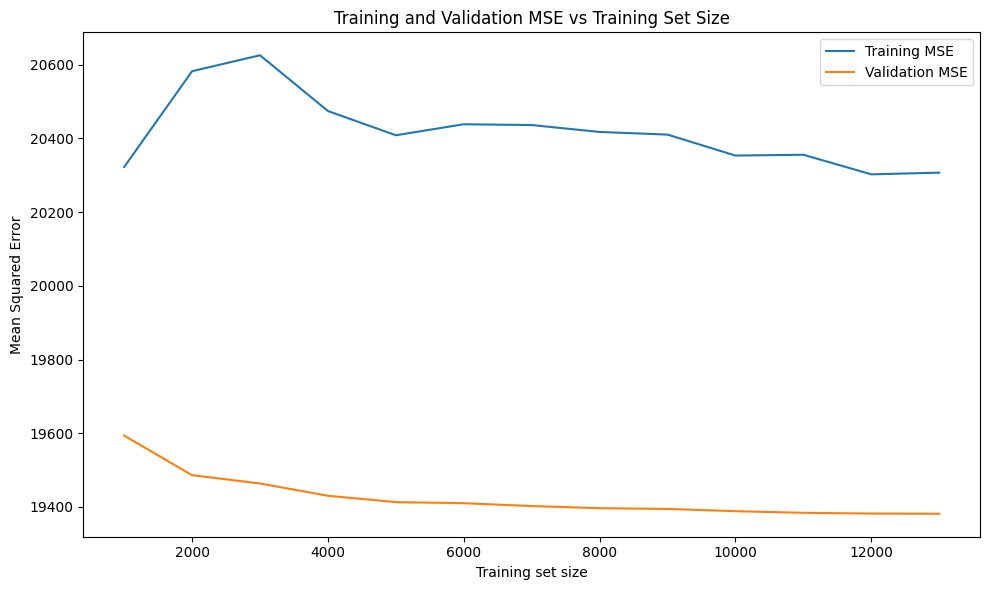

In [14]:
# calculate mse score
#WILL PROB DELETE THIS AS IT DOESNT SHOW THE TRAINING MSE TREND
fig = plt.figure(figsize=(10, 6))

plt.plot(sizes, train_mses, label = "Training MSE")
plt.plot(sizes, val_mses, label = "Validation MSE")
plt.title("Training and Validation MSE vs Training Set Size")
plt.xlabel("Training set size")
plt.ylabel("Mean Squared Error")
plt.legend()

plt.tight_layout()
plt.show()

## MSE plotting and comparison

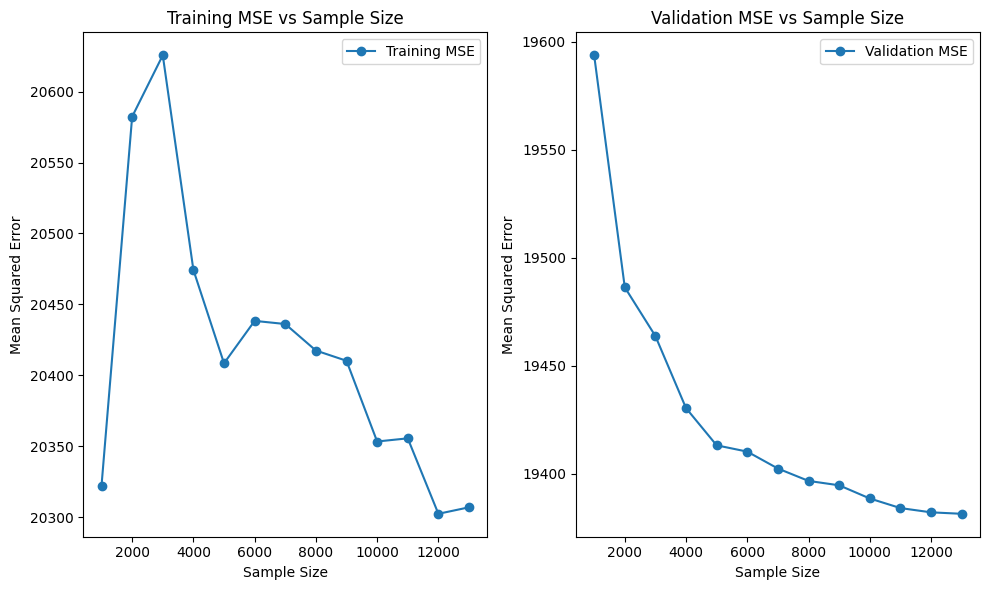

In [13]:
# code for showing the MSE score

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 6))

ax1.plot(sizes, train_mses, label='Training MSE', marker='o')
ax1.set_xlabel('Sample Size')
ax1.set_ylabel('Mean Squared Error')
ax1.set_title('Training MSE vs Sample Size')
ax1.legend()

ax2.plot(sizes, val_mses, label='Validation MSE', marker='o')
ax2.set_xlabel('Sample Size')
ax2.set_ylabel('Mean Squared Error')
ax2.set_title('Validation MSE vs Sample Size')
ax2.legend()

plt.tight_layout()
plt.show()
#write text comparing both behaviours

## Quadratic regression - Bike sharing dataset

In [16]:
qtrain_mses = []
qval_mses = []

for s in sizes:
    qtrial_tmse = []
    qtrial_vmse = []
    for n in range(repeats):
        #split the training pool into a training set of size s
        X_train, _, y_train, _ = train_test_split(X_train_pool, y_train_pool, train_size=s, random_state=n)
        qmodel = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
        qmodel.fit(X_train, y_train)    #fitting a linear model on the training data

        #predting the training and validation data
        qtrain_pred = qmodel.predict(X_train)
        qval_pred = qmodel.predict(X_val)
        
        qmse_train = mean_squared_error(y_train, qtrain_pred)
        qmse_val = mean_squared_error(y_val, qval_pred)

        qtrial_tmse.append(qmse_train)
        qtrial_vmse.append(qmse_val)

    #printing the avg mse for each training set size   
    print(f"Sample Size {s}: \n Training Mean Squared Error = {np.mean(qtrial_tmse):.3f} \n Validation Mean Squared Error = {np.mean(qtrial_vmse):.3f}")
    print("\n")

    #appending the avg mse for each training size so we can later plot them
    qtrain_mses.append(np.mean(qtrial_tmse))
    qval_mses.append(np.mean(qtrial_vmse))

Sample Size 1000: 
 Training Mean Squared Error = 14027.491 
 Validation Mean Squared Error = 16109.725


Sample Size 2000: 
 Training Mean Squared Error = 14648.239 
 Validation Mean Squared Error = 15125.799


Sample Size 3000: 
 Training Mean Squared Error = 14861.157 
 Validation Mean Squared Error = 14843.172


Sample Size 4000: 
 Training Mean Squared Error = 14818.359 
 Validation Mean Squared Error = 14713.162


Sample Size 5000: 
 Training Mean Squared Error = 14820.328 
 Validation Mean Squared Error = 14665.470


Sample Size 6000: 
 Training Mean Squared Error = 14883.233 
 Validation Mean Squared Error = 14628.001


Sample Size 7000: 
 Training Mean Squared Error = 14910.156 
 Validation Mean Squared Error = 14594.017


Sample Size 8000: 
 Training Mean Squared Error = 14907.284 
 Validation Mean Squared Error = 14568.388


Sample Size 9000: 
 Training Mean Squared Error = 14922.981 
 Validation Mean Squared Error = 14555.600


Sample Size 10000: 
 Training Mean Squared Err

## MSE plotting and comparison - quadratic regression

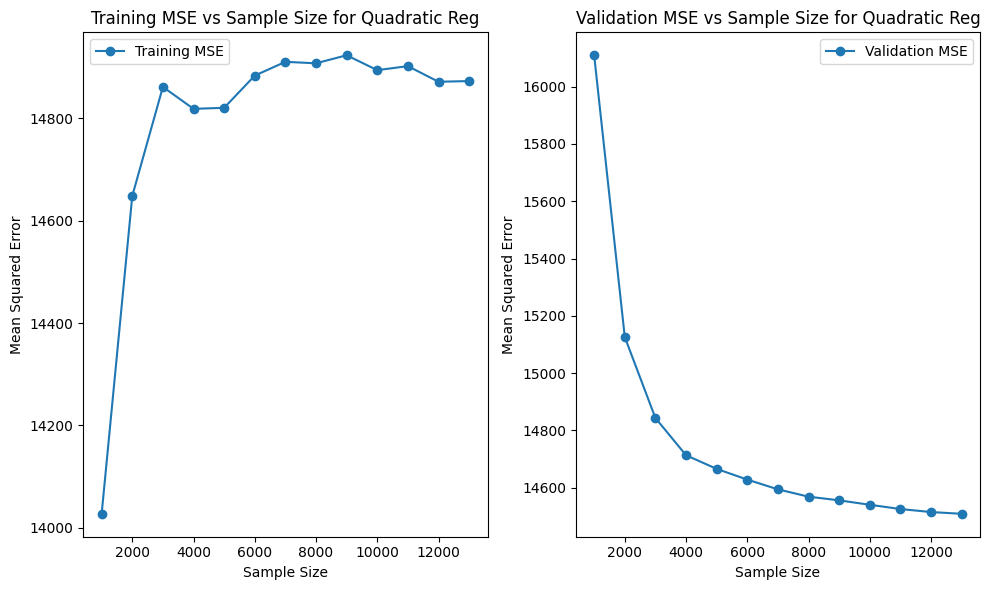

In [17]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 6))

ax1.plot(sizes, qtrain_mses, label='Training MSE', marker='o')
ax1.set_xlabel('Sample Size')
ax1.set_ylabel('Mean Squared Error')
ax1.set_title('Training MSE vs Sample Size for Quadratic Reg')
ax1.legend()

ax2.plot(sizes, qval_mses, label='Validation MSE', marker='o')
ax2.set_xlabel('Sample Size')
ax2.set_ylabel('Mean Squared Error')
ax2.set_title('Validation MSE vs Sample Size for Quadratic Reg')
ax2.legend()

plt.tight_layout()
plt.show()

## Cross-validation between linear regression and quadratic regression

In [18]:
lscores = cross_val_score(model, X_train_pool, y_train_pool, cv=5, scoring='neg_mean_squared_error')

qscores = cross_val_score(qmodel, X_train_pool, y_train_pool, cv=5, scoring='neg_mean_squared_error')

lin_cv_mse = -np.mean(lscores)
quad_cv_mse = -np.mean(qscores)

print(f"Linear Regression Cross-Validation MSE: {lin_cv_mse:.3f}")
print(f"Quadratic Regression Cross-Validation MSE: {quad_cv_mse:.3f}")

Linear Regression Cross-Validation MSE: 20326.616
Quadratic Regression Cross-Validation MSE: 15055.121


## Classification - Wine dataset

Import data

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wine = fetch_ucirepo(id=109) 
  
# data (as pandas dataframes) 
X = wine.data.features 
y = wine.data.targets 
  
# check for missing values  
print(X.info()) 
  
# variable information 
print(wine.variables)


<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Alcohol                       178 non-null    float64
 1   Malicacid                     178 non-null    float64
 2   Ash                           178 non-null    float64
 3   Alcalinity_of_ash             178 non-null    float64
 4   Magnesium                     178 non-null    int64  
 5   Total_phenols                 178 non-null    float64
 6   Flavanoids                    178 non-null    float64
 7   Nonflavanoid_phenols          178 non-null    float64
 8   Proanthocyanins               178 non-null    float64
 9   Color_intensity               178 non-null    float64
 10  Hue                           178 non-null    float64
 11  0D280_0D315_of_diluted_wines  178 non-null    float64
 12  Proline                       178 non-null    int64  
dtypes: float64(11), 

In [4]:
print(X.columns)

Index(['Alcohol', 'Malicacid', 'Ash', 'Alcalinity_of_ash', 'Magnesium',
       'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols',
       'Proanthocyanins', 'Color_intensity', 'Hue',
       '0D280_0D315_of_diluted_wines', 'Proline'],
      dtype='str')


Divide train+test sets

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [6]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

In [8]:
from sklearn.metrics import log_loss

sizes=[10, 20, 50, 100]
repeats=15
train_losses, val_losses = [], []


for s in sizes:
    tr, va = [], []
    for r in range(repeats):
        X_sample, _, y_sample, _ = train_test_split(
            X_train, y_train, train_size=s, random_state=r, stratify=y_train
        )

        model.fit(X_sample, y_sample)

        val_loss = model.predict_proba(X_test)
        tr.append(log_loss(y_sample, model.predict_proba(X_sample)))
        va.append(log_loss(y_test, val_loss))

    train_losses.append(np.mean(tr))
    val_losses.append(np.mean(va))

       

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\va

Plotting

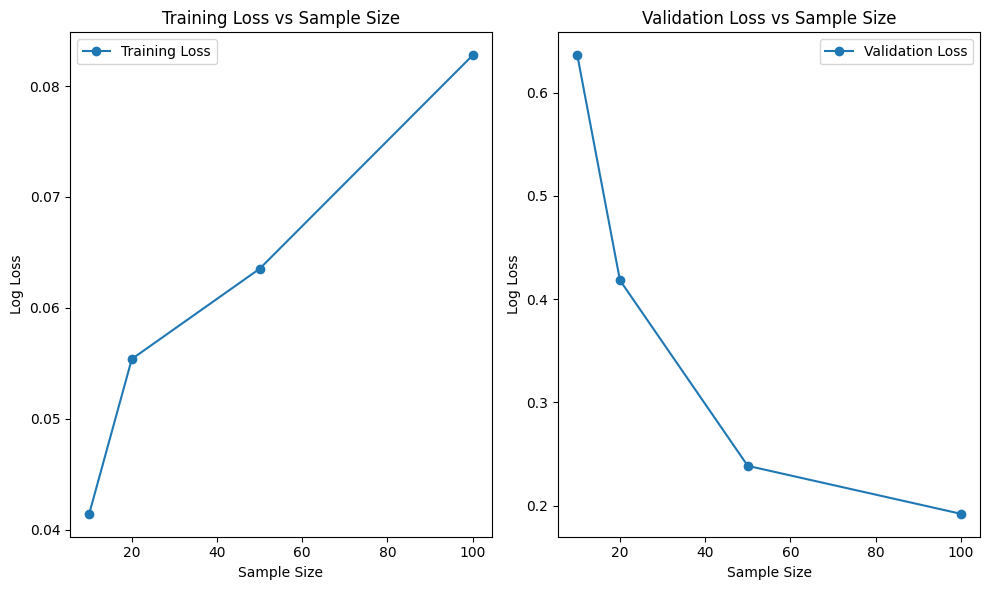

In [9]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 6))

ax1.plot(sizes, train_losses, label='Training Loss', marker='o')
ax1.set_xlabel('Sample Size')
ax1.set_ylabel('Log Loss')
ax1.set_title('Training Loss vs Sample Size')
ax1.legend()

ax2.plot(sizes, val_losses, label='Validation Loss', marker='o')
ax2.set_xlabel('Sample Size')
ax2.set_ylabel('Log Loss')
ax2.set_title('Validation Loss vs Sample Size')
ax2.legend()

plt.tight_layout()
plt.show()

Quadratic regression

In [13]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
import numpy as np

quad_loss = []
quad_val_loss = []
quad_model = make_pipeline(PolynomialFeatures(degree=2), LogisticRegression())

for s in sizes:
    q_tr, q_va = [], []
    for r in range(repeats):
        X_sample, _, y_sample, _ = train_test_split(X_train, y_train, train_size=s, random_state=r, stratify=y_train)
        
        quad_model.fit(X_sample, y_sample)    #fitting a linear model on the training data
        q_val_loss = quad_model.predict_proba(X_test)
        q_tr.append(log_loss(y_sample, model.predict_proba(X_sample)))
        q_va.append(log_loss(y_test, q_val_loss))

    quad_loss.append(np.mean(q_tr))
    quad_val_loss.append(np.mean(q_va))




c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\va

Cross-validation

In [16]:

from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score

log_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_log_loss')

quad_scores = cross_val_score(quad_model, X_train, y_train, cv=5, scoring='neg_log_loss')

log_cv_loss = -np.mean(log_scores)
quad_cv_loss = -np.mean(quad_scores)


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\va

## Classification - Online Retail dataset